<a href="https://colab.research.google.com/github/adarshkray2006/ml/blob/main/supervised_classification_project_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Supervised Classification: Breast Cancer Diagnosis
**Goal:** Build and evaluate supervised classification models, compare Logistic Regression and Random Forest, and report Accuracy, Precision, Recall, F1-score, and ROC-AUC.

**Dataset:** Wisconsin Breast Cancer dataset included with scikit-learn. The target is binary: malignant vs. benign. No external download is required.

**Workflow:** Load data → inspect/preprocess → stratified train/test split → cross-validation on training data → compare models → evaluate the selected model once on the held-out test set.

In [ ]:
# If needed in a fresh environment, uncomment:
# %pip install pandas numpy matplotlib seaborn scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    ConfusionMatrixDisplay, RocCurveDisplay, classification_report
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")


## 1. Load and inspect the dataset

In [ ]:
data = load_breast_cancer(as_frame=True)
X = data.data.copy()
# sklearn's original target: 0 = malignant, 1 = benign.
# Convert to the clearer positive class: 1 = malignant, 0 = benign.
y = (data.target == 0).astype(int)
target_names = {0: "Benign", 1: "Malignant"}

print("Feature matrix shape:", X.shape)
print("Target counts (0=benign, 1=malignant):")
print(y.value_counts().rename(index=target_names))
display(X.head())
print("\\nMissing values:", int(X.isna().sum().sum()))


Feature matrix shape: (569, 30)
Target counts (0=benign, 1=malignant):
target
Benign       357
Malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


\nMissing values: 0


## 2. Exploratory data analysis
The chart shows the class distribution. A stratified split helps preserve the class proportions in training and test sets.

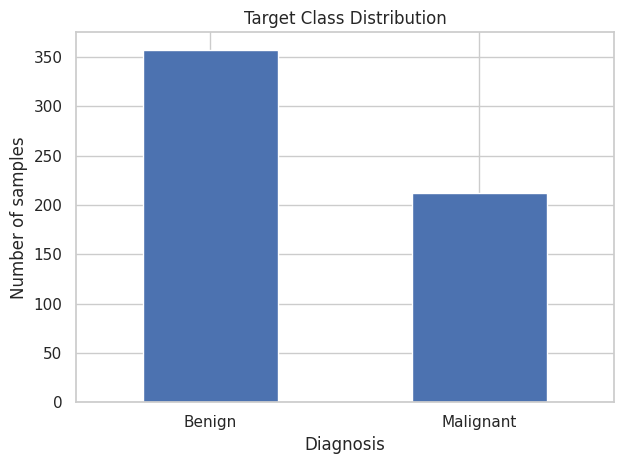

In [ ]:
counts = y.map(target_names).value_counts()
ax = counts.plot(kind="bar", rot=0)
ax.set_title("Target Class Distribution")
ax.set_xlabel("Diagnosis")
ax.set_ylabel("Number of samples")
plt.tight_layout()
plt.show()


## 3. Train/test split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training samples:", X_train.shape[0])
print("Test samples:", X_test.shape[0])
print("Training malignant proportion:", round(y_train.mean(), 3))
print("Test malignant proportion:", round(y_test.mean(), 3))


Training samples: 455
Test samples: 114
Training malignant proportion: 0.374
Test malignant proportion: 0.368


## 4. Define models and preprocessing
Preprocessing is placed inside each pipeline so that imputation/scaling is learned only from each training fold, avoiding data leakage. Logistic Regression uses standardization; Random Forest does not require feature scaling but shares a safe imputation step.

In [ ]:
logistic_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
])

forest_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE, class_weight="balanced"
    ))
])

models = {
    "Logistic Regression": logistic_pipeline,
    "Random Forest": forest_pipeline
}


## 5. Cross-validation on training data
Use 5-fold stratified cross-validation. The test set remains untouched during model comparison.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_rows = []
for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train, cv=cv, scoring=scoring,
        return_train_score=False, n_jobs=-1
    )
    row = {"Model": name}
    for metric in scoring:
        row[f"{metric}_mean"] = scores[f"test_{metric}"].mean()
        row[f"{metric}_std"] = scores[f"test_{metric}"].std()
    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows).sort_values("roc_auc_mean", ascending=False)
display(cv_results.round(4))


,Model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,Logistic Regression,0.9736,0.0149,0.9771,0.0280,0.9529,0.0399,0.9640,0.0207,0.9958,0.0047
1,Random Forest,0.9626,0.0132,0.9592,0.0286,0.9412,0.0322,0.9495,0.0178,0.9891,0.0070


## 6. Compare cross-validation results
These plots show mean CV metrics. Use the printed table above for exact means and standard deviations.

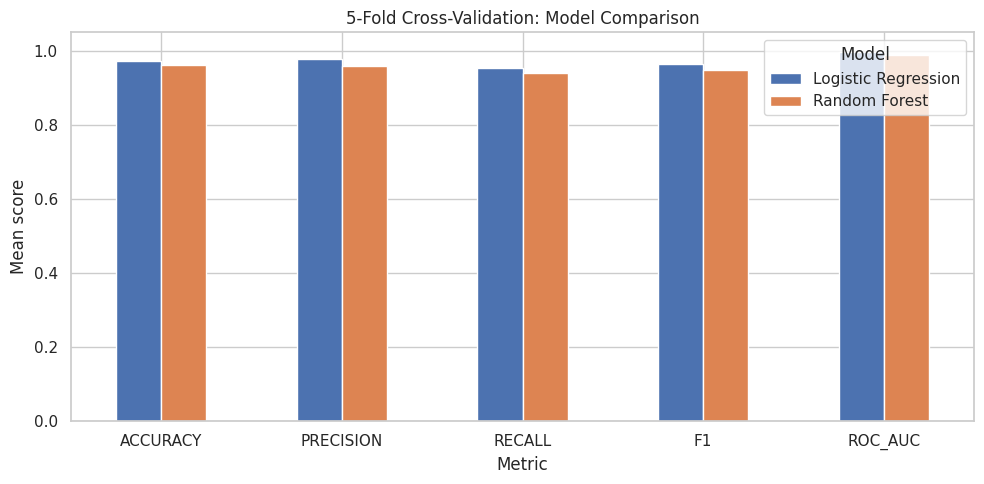

In [ ]:
plot_metrics = ["accuracy_mean", "precision_mean", "recall_mean", "f1_mean", "roc_auc_mean"]
plot_df = cv_results.set_index("Model")[plot_metrics].rename(columns=lambda c: c.replace("_mean", "").upper())
ax = plot_df.T.plot(kind="bar", figsize=(10, 5))
ax.set_title("5-Fold Cross-Validation: Model Comparison")
ax.set_ylabel("Mean score")
ax.set_ylim(0, 1.05)
ax.set_xlabel("Metric")
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.tight_layout()
plt.show()


## 7. Fit the selected model and evaluate on the held-out test set
For this example, select the model with the highest mean cross-validation ROC-AUC. The test set is used only for this final evaluation.

In [ ]:
best_name = cv_results.iloc[0]["Model"]
best_model = models[best_name]
best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]  # probability of malignant (positive class)

test_metrics = {
    "Model": best_name,
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}
test_results = pd.DataFrame([test_metrics])
display(test_results.round(4))
print(classification_report(y_test, y_pred, target_names=["Benign", "Malignant"], zero_division=0))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.9649,0.975,0.9286,0.9512,0.996


              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



## 8. Confusion matrix and ROC curve

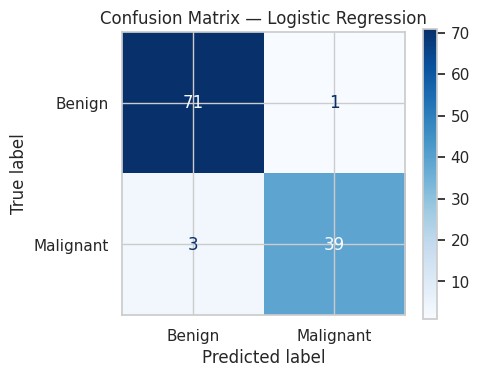

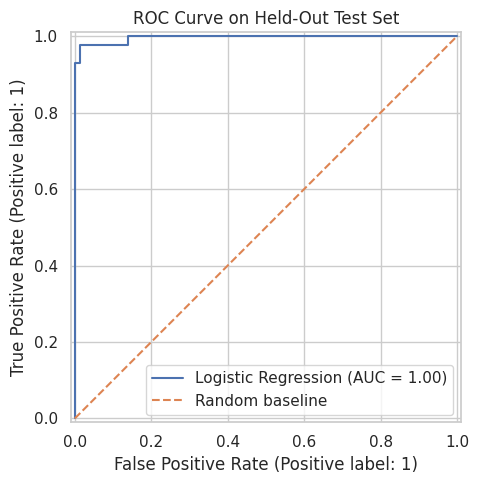

In [ ]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Benign", "Malignant"], cmap="Blues", ax=ax
)
ax.set_title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, y_prob, ax=ax, name=best_name)
ax.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
ax.set_title("ROC Curve on Held-Out Test Set")
ax.legend()
plt.tight_layout()
plt.show()


## 9. Short report (complete after running all cells)
Replace the bracketed placeholders below with the values produced by the notebook.

### Objective
The objective was to train and compare supervised classification models for predicting whether a breast tumour is malignant or benign.

### Dataset and preprocessing
The project used scikit-learn's Wisconsin Breast Cancer dataset, containing numeric diagnostic features. The target was encoded as 1 for malignant and 0 for benign. An 80/20 stratified train/test split was used. Median imputation was included in the model pipelines, and StandardScaler was applied to Logistic Regression. Five-fold stratified cross-validation was performed on the training set.

### Models
- **Logistic Regression:** a linear classification baseline; features were standardized.
- **Random Forest:** an ensemble of decision trees that can capture nonlinear relationships.

### Results
Cross-validation results are displayed in the `cv_results` table. The model selected by mean CV ROC-AUC was **[best model name]**. On the held-out test set, it achieved:
- Accuracy: **[value]**
- Precision: **[value]**
- Recall: **[value]**
- F1-score: **[value]**
- ROC-AUC: **[value]**

### Model selection and conclusion
The selected model had the highest mean 5-fold CV ROC-AUC, then was evaluated once on the held-out test set. Accuracy describes overall correctness; precision measures how many predicted malignant cases were truly malignant; recall measures how many actual malignant cases were detected; F1 balances precision and recall; ROC-AUC measures ranking ability across thresholds. In a medical context, false negatives can be especially important, so recall and clinical validation should be considered rather than accuracy alone.

### Limitations
This is an educational exercise using a public benchmark dataset, not a clinical diagnostic tool. Results may differ with software versions and should not be generalized to real-world medical decisions.


## 10. Optional: save the test metrics
Run this cell to save a CSV containing the final held-out test metrics.

In [ ]:
test_results.to_csv("classification_test_metrics.csv", index=False)
cv_results.to_csv("classification_cross_validation_results.csv", index=False)
print("Saved classification_test_metrics.csv and classification_cross_validation_results.csv")


Saved classification_test_metrics.csv and classification_cross_validation_results.csv
